In [70]:
import matplotlib.pyplot as plt
import os
import numpy as np
import pandas as pd 
import kagglehub
from pathlib import Path

In [90]:
house_data = pd.read_csv('Housing.csv')

# stat_house = house_data.describe()
house_datary= np.array(house_data[['area','price']])
house_datary

array([[    7420, 13300000],
       [    8960, 12250000],
       [    9960, 12250000],
       ...,
       [    3620,  1750000],
       [    2910,  1750000],
       [    3850,  1750000]], shape=(545, 2))

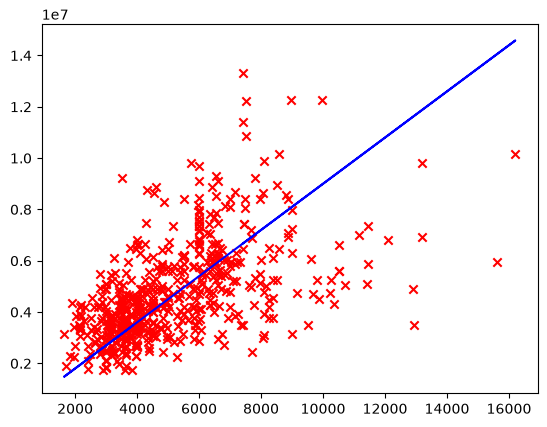

In [101]:
x = house_datary[:,0]
y = house_datary[:,1]

w = 900
b = 300 

first_reg = w*x 

first_reg

plt.scatter(x,y, c = 'red' , marker = 'x')
plt.plot(x,first_reg, c = 'blue')

In [109]:
m = len(x)

cost_func = (1 / (2 * m)) * np.sum((first_reg - y)**2)
cost_func

np.float64(1704011560301.468)

TypeError: `bins` must be an integer, a string, or an array

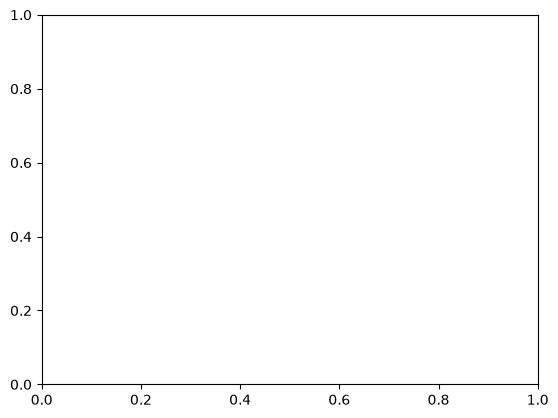

In [111]:
plt.hist(first_reg, cost_func)

Loop 0: Cost = 13106916364659.27, Weight w = 267.2292
Loop 10: Cost = 1679783758096.40, Weight w = 841.7851
Loop 20: Cost = 1673385660767.71, Weight w = 855.3805
Loop 30: Cost = 1673382078447.38, Weight w = 855.7022
Loop 40: Cost = 1673382076441.62, Weight w = 855.7098
Loop 50: Cost = 1673382076440.50, Weight w = 855.7099
Loop 60: Cost = 1673382076440.50, Weight w = 855.7099
Loop 70: Cost = 1673382076440.50, Weight w = 855.7099
Loop 80: Cost = 1673382076440.50, Weight w = 855.7099
Loop 90: Cost = 1673382076440.50, Weight w = 855.7099


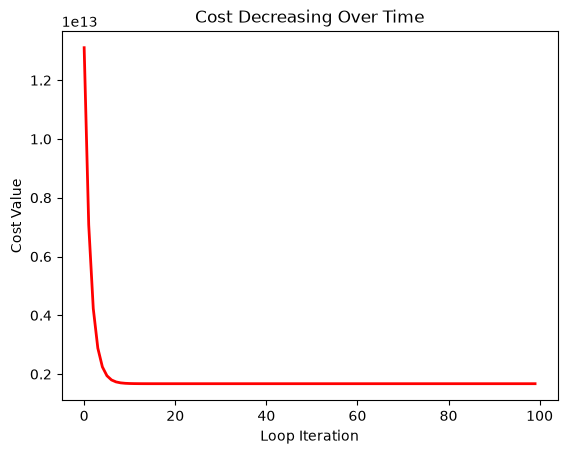

In [112]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Initialize variables
w = 0.0  # Starting weight
b = 0.0  # Starting bias (optional, set to 0 for now)
learning_rate = 0.00000001  # Small step size (alpha)
epochs = 100  # Number of times to loop

m = len(x)  # Number of data points

# Empty lists to store values for plotting later
cost_history = []
w_history = []

# 2. The Training Loop
for i in range(epochs):
    # Calculate predictions (y = wx + b)
    first_reg = (w * x) + b

    # Calculate the Cost (Mean Squared Error)
    cost_func = (1 / (2 * m)) * np.sum((first_reg - y) ** 2)
    cost_history.append(cost_func)
    w_history.append(w)

    # Calculate Gradients (Derivative of cost with respect to w)
    w_gradient = (1 / m) * np.sum((first_reg - y) * x)

    # Update Weight (The changing step)
    w = w - (learning_rate * w_gradient)

    # Print progress every 10 loops
    if i % 10 == 0:
        print(f"Loop {i}: Cost = {cost_func:.2f}, Weight w = {w:.4f}")

# 3. Plot the changing cost over time
plt.plot(cost_history, color="red", linewidth=2)
plt.xlabel("Loop Iteration")
plt.ylabel("Cost Value")
plt.title("Cost Decreasing Over Time")
plt.show()


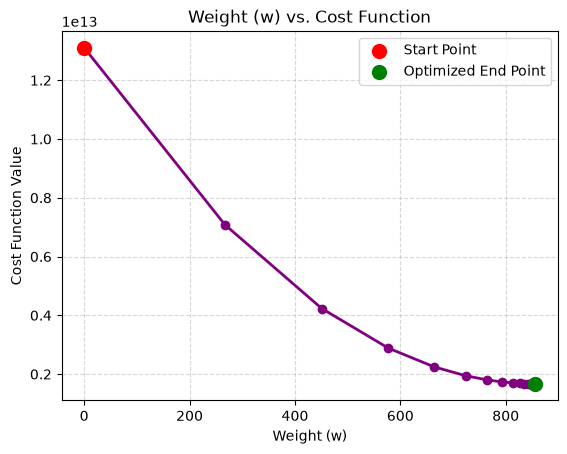

In [113]:
import matplotlib.pyplot as plt

# Use the history lists generated inside your training loop
# X-axis: Weight values that the loop tested
# Y-axis: The resulting cost for each weight
plt.plot(w_history, cost_history, color='purple', marker='o', linestyle='-', linewidth=2)

# Mark the starting point and final ending point
plt.scatter(w_history[0], cost_history[0], color='red', s=100, label='Start Point', zorder=5)
plt.scatter(w_history[-1], cost_history[-1], color='green', s=100, label='Optimized End Point', zorder=5)

# Add clear labels and title
plt.xlabel("Weight (w)")
plt.ylabel("Cost Function Value")
plt.title("Weight (w) vs. Cost Function")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Display the U-shape path
plt.show()
